<style>
:root {
  --dal-primary:#B91C4B; --dal-dark:#7A0F31; --dal-deep:#4D091E;
  --dal-rose:#F8E9EE; --dal-cream:#FFF9F6; --dal-ink:#171418; --dal-muted:#6F6268;
  --dal-border:#E8D9DE;
}
.rendered_html, .jp-RenderedHTMLCommon { color:var(--dal-ink); line-height:1.62; }
.rendered_html h2, .jp-RenderedHTMLCommon h2 {
  color:var(--dal-deep); font-weight:800; border-bottom:2px solid var(--dal-rose); padding-bottom:.32em; margin-top:1.8em;
}
.rendered_html h3, .jp-RenderedHTMLCommon h3 { color:var(--dal-primary); font-weight:750; }
.rendered_html a, .jp-RenderedHTMLCommon a { color:var(--dal-primary); }
.rendered_html blockquote, .jp-RenderedHTMLCommon blockquote {
  border-left:4px solid var(--dal-primary); background:var(--dal-cream); padding:.7em 1em; color:var(--dal-ink);
}
.rendered_html table, .jp-RenderedHTMLCommon table { border-collapse:separate; border-spacing:0; overflow:hidden; border:1px solid var(--dal-border); border-radius:10px; }
.rendered_html th, .jp-RenderedHTMLCommon th { background:var(--dal-rose); color:var(--dal-deep); font-weight:750; }
.rendered_html code, .jp-RenderedHTMLCommon code { color:var(--dal-primary-dark); }
.dal-cover {
  background:linear-gradient(135deg,#4D091E 0%,#7A0F31 42%,#B91C4B 100%);
  padding:30px 34px 28px; border-radius:22px; color:white; margin:6px 0 24px;
  box-shadow:0 16px 42px rgba(77,9,30,.18); position:relative; overflow:hidden;
}
.dal-cover:after { content:''; position:absolute; width:260px; height:260px; border:1px solid rgba(255,255,255,.17); border-radius:50%; right:-95px; top:-110px; box-shadow:0 0 0 28px rgba(255,255,255,.035), 0 0 0 58px rgba(255,255,255,.025); }
.dal-brand-row { display:flex; align-items:center; justify-content:space-between; gap:20px; position:relative; z-index:2; }
.dal-logo { height:48px; max-width:150px; object-fit:contain; object-position:left center; }
.dal-brand-fallback { font-size:20px; font-weight:800; letter-spacing:.3px; }
.dal-kicker { font-size:12px; letter-spacing:2.1px; text-transform:uppercase; color:#F7CAD7; font-weight:800; margin-top:24px; position:relative; z-index:2; }
.dal-title { font-size:38px; font-weight:850; margin-top:7px; line-height:1.12; max-width:850px; position:relative; z-index:2; }
.dal-subtitle { font-size:17px; color:#FFEAF0; margin-top:10px; max-width:820px; position:relative; z-index:2; }
.dal-chips { display:flex; gap:9px; flex-wrap:wrap; margin-top:19px; position:relative; z-index:2; }
.dal-chip { background:rgba(255,255,255,.13); border:1px solid rgba(255,255,255,.16); padding:6px 11px; border-radius:999px; font-size:12px; font-weight:650; }
.dal-chip-solid { background:white; color:#7A0F31; border-color:white; }
.dal-site { color:#FFEAF0; font-size:12px; font-weight:650; text-decoration:none; }
.dal-callout { background:#F8E9EE; border-left:5px solid #B91C4B; padding:14px 16px; border-radius:10px; margin:14px 0; color:#171418; }
.dal-callout b { color:#7A0F31; }
.dal-footer { margin-top:28px; padding:15px 18px; border-radius:13px; background:#4D091E; color:#FFEAF0; display:flex; align-items:center; justify-content:space-between; gap:16px; }
.dal-footer a { color:white !important; font-weight:700; }
</style>
<div class="dal-cover">
  <div class="dal-brand-row">
    <div style="display:flex;align-items:center;gap:16px">
      <img class="dal-logo" src="https://daldata.ai/Dal-white.svg" alt="Dal | دال logo" onerror="this.style.display='none'" />
      <div class="dal-brand-fallback">DAL <span style="opacity:.65">|</span> دال</div>
    </div>
    <a class="dal-site" href="https://daldata.ai">daldata.ai</a>
  </div>
  <div class="dal-kicker">DATA & AI LEARNING SERIES · NOTEBOOK 02 / 06</div>
  <div class="dal-title">02 · Data Processing Architectures</div>
  <div class="dal-subtitle">Batch, micro-batch, streaming, state, windows, latency, and reliability.</div>
  <div class="dal-chips">
    <span class="dal-chip dal-chip-solid">DAL</span><span class="dal-chip">Batch</span><span class="dal-chip">Streaming</span><span class="dal-chip">Reliability</span><span class="dal-chip">Hands-on</span><span class="dal-chip">Production mindset</span>
  </div>
</div>
<div style="font-size:13px;color:#6F6268;margin:-10px 4px 22px">Guiding a generation of data leaders · A professional learning notebook by <b style="color:#7A0F31">Dal | دال</b></div>

### What you will be able to do
- Choose batch, micro-batch, or streaming based on business latency and complexity.
- Explain event time, processing time, state, windows, and late data.
- Simulate incremental processing with state and idempotent event handling.
- Reason about throughput, partitions, backpressure, delivery semantics, and recovery.
- Translate a business SLA into an architecture decision.

**Level:** Intermediate  
**Dataset:** reproducible synthetic commerce data; no external downloads required.

<div class="dal-callout"><b>DAL Principle</b><br>Real-time is a business requirement, not a prestige architecture. Use the slowest architecture that still meets the decision deadline.</div>

## 1. Environment & events

In [1]:
import json
import re
import sqlite3
import time
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (9, 4)

# Dal visual system — aligned with daldata.ai branding
DAL_PRIMARY = '#B91C4B'
DAL_DARK = '#7A0F31'
DAL_DEEP = '#4D091E'
DAL_ROSE = '#F8E9EE'
DAL_INK = '#171418'
plt.rcParams.update({
    'figure.figsize': (9, 4),
    'axes.prop_cycle': plt.cycler(color=[DAL_PRIMARY, DAL_DARK, '#D75D7E', '#8F5368', '#D8A0B0']),
    'axes.titleweight': 'bold',
    'axes.titlecolor': DAL_DEEP,
    'axes.labelcolor': DAL_INK,
    'axes.edgecolor': '#D7C5CB',
    'grid.color': '#EADDE1',
    'grid.alpha': 0.65,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

SEED = 42
rng = np.random.default_rng(SEED)
print('DAL | دال learning environment ready')

DAL | دال learning environment ready


In [3]:
# Reproducible synthetic commerce dataset used throughout the daldata.ai series.
rng = np.random.default_rng(SEED)

products = {
    'Laptop': ('Electronics', 900),
    'Phone': ('Electronics', 600),
    'Headphones': ('Electronics', 85),
    'Monitor': ('Electronics', 260),
    'Desk': ('Furniture', 320),
    'Chair': ('Furniture', 180),
    'Lamp': ('Furniture', 55),
    'Notebook': ('Stationery', 9),
    'Pen Set': ('Stationery', 12),
    'Backpack': ('Accessories', 70),
}

cities = ['Riyadh', 'Jeddah', 'Dammam', 'Makkah', 'Madinah']
segments = ['Consumer', 'SMB', 'Enterprise']
channels = ['web', 'mobile', 'partner']

customers = pd.DataFrame({
    'customer_id': np.arange(1, 301),
    'city': rng.choice(cities, 300, p=[0.34, 0.26, 0.16, 0.13, 0.11]),
    'segment': rng.choice(segments, 300, p=[0.58, 0.30, 0.12]),
    'signup_date': pd.to_datetime('2025-01-01') + pd.to_timedelta(rng.integers(0, 365, 300), unit='D')
})

n = 6500
product_names = rng.choice(list(products), n)
base_prices = np.array([products[p][1] for p in product_names], dtype=float)
orders = pd.DataFrame({
    'order_id': np.arange(100001, 100001 + n),
    'customer_id': rng.integers(1, 301, n),
    'order_ts': pd.to_datetime('2026-01-01') + pd.to_timedelta(rng.integers(0, 180*24*60, n), unit='m'),
    'product': product_names,
    'quantity': rng.integers(1, 6, n),
    'channel': rng.choice(channels, n, p=[0.48, 0.42, 0.10]),
    'status': rng.choice(['completed','cancelled','returned'], n, p=[0.84,0.10,0.06]),
})
orders['category'] = orders['product'].map({k:v[0] for k,v in products.items()})
orders['unit_price'] = np.round(base_prices * rng.normal(1.0, 0.07, n), 2)
orders['discount_pct'] = rng.choice([0, 0.05, 0.10, 0.15, 0.20], n, p=[0.50,0.18,0.17,0.10,0.05])

# Inject realistic quality issues on purpose.
missing_idx = rng.choice(orders.index, 90, replace=False)
orders.loc[missing_idx, 'unit_price'] = np.nan
orders = pd.concat([orders, orders.sample(45, random_state=SEED)], ignore_index=True)

# Add a few invalid-looking values for validation labs.
orders.loc[rng.choice(orders.index, 8, replace=False), 'quantity'] = 0

print(f'orders: {orders.shape[0]:,} rows | customers: {customers.shape[0]:,} rows')
orders.head(3)

orders: 6,545 rows | customers: 300 rows


,order_id,customer_id,order_ts,product,quantity,channel,status,category,unit_price,discount_pct
0,100001,194,2026-04-21 20:58:00,Chair,1,mobile,completed,Furniture,170.43,0.15
1,100002,215,2026-04-07 06:23:00,Headphones,2,mobile,cancelled,Electronics,89.10,0.00
2,100003,81,2026-04-03 02:35:00,Headphones,4,mobile,completed,Electronics,87.28,0.05


In [4]:
events = (orders.drop_duplicates('order_id')
          .sort_values('order_ts')
          .reset_index(drop=True)
          .copy())
events['event_value'] = events['quantity'] * events['unit_price'].fillna(0) * (1 - events['discount_pct'])
events[['order_id','order_ts','customer_id','status','event_value']].head()

,order_id,order_ts,customer_id,status,event_value
0,105936,2026-01-01 00:03:00,52,completed,49.29
1,105551,2026-01-01 01:24:00,159,returned,284.07
2,104193,2026-01-01 01:40:00,129,completed,49.44
3,105890,2026-01-01 01:56:00,115,completed,28.41
4,105731,2026-01-01 02:06:00,92,completed,940.15


## 2. Processing models at a glance

| Model | Typical freshness | Operational complexity | Good fit |
|---|---:|---:|---|
| Batch | hours/daily | low | finance close, historical reporting |
| Micro-batch | minutes | medium | dashboards, incremental ETL |
| Streaming | seconds/sub-seconds | high | fraud, alerts, live operations |

### Visual map · Movement pattern ≠ storage pattern
<div style="margin:18px 0 24px"><svg viewBox="0 0 1100 360" width="100%" role="img" aria-label="Processing models and storage targets">
<rect x="5" y="5" width="1090" height="350" rx="24" fill="#FFF9F6" stroke="#E8D9DE"/>
<text x="50" y="55" font-size="24" font-weight="800" fill="#4D091E">Processing and storage are separate decisions</text>
<text x="50" y="83" font-size="14" fill="#6F6268">Batch, micro-batch and streaming describe how data moves; warehouse, lake and lakehouse describe how analytics data is organized.</text>
<g font-family="Arial">
<rect x="50" y="125" width="220" height="58" rx="16" fill="#F8E9EE" stroke="#B91C4B"/><text x="120" y="161" font-size="18" font-weight="800" fill="#7A0F31">BATCH</text>
<rect x="50" y="205" width="220" height="58" rx="16" fill="#F8E9EE" stroke="#B91C4B"/><text x="93" y="241" font-size="18" font-weight="800" fill="#7A0F31">MICRO-BATCH</text>
<rect x="50" y="285" width="220" height="58" rx="16" fill="#F8E9EE" stroke="#B91C4B"/><text x="105" y="321" font-size="18" font-weight="800" fill="#7A0F31">STREAMING</text>
<path d="M285 154 L520 154" stroke="#B91C4B" stroke-width="4"/><path d="M285 234 L520 234" stroke="#B91C4B" stroke-width="4"/><path d="M285 314 L520 314" stroke="#B91C4B" stroke-width="4"/>
<rect x="540" y="112" width="170" height="70" rx="18" fill="#fff" stroke="#E8D9DE"/><text x="565" y="146" font-size="17" font-weight="800" fill="#4D091E">Warehouse</text><text x="565" y="169" font-size="12" fill="#6F6268">SQL / BI serving</text>
<rect x="540" y="205" width="170" height="70" rx="18" fill="#fff" stroke="#E8D9DE"/><text x="590" y="239" font-size="17" font-weight="800" fill="#4D091E">Lake</text><text x="567" y="262" font-size="12" fill="#6F6268">raw/open storage</text>
<rect x="540" y="298" width="170" height="46" rx="18" fill="#fff" stroke="#E8D9DE"/><text x="573" y="327" font-size="17" font-weight="800" fill="#4D091E">Lakehouse</text>
<text x="770" y="145" font-size="15" font-weight="750" fill="#7A0F31">Example combinations</text>
<text x="770" y="178" font-size="13" fill="#6F6268">daily ETL → warehouse</text><text x="770" y="207" font-size="13" fill="#6F6268">event ingest → lake</text><text x="770" y="236" font-size="13" fill="#6F6268">stream → lakehouse table</text><text x="770" y="265" font-size="13" fill="#6F6268">batch ML features → lakehouse</text><text x="770" y="294" font-size="13" fill="#6F6268">CDC → warehouse + lake</text>
</g></svg></div>

### Batch processing: complete input, one scheduled computation

In [5]:
clean = events.dropna(subset=['unit_price']).query('quantity > 0').copy()
t0=time.perf_counter()
batch_kpi=(clean.query("status == 'completed'")
           .groupby('category')['event_value'].sum()
           .sort_values(ascending=False))
print(f'elapsed: {(time.perf_counter()-t0)*1000:.2f} ms')
batch_kpi

elapsed: 4.58 ms


category
Electronics   2,881,831.77
Furniture       845,794.26
Accessories     102,922.59
Stationery       32,161.34
Name: event_value, dtype: float64

### Micro-batch: bounded slices repeated frequently

In [6]:
chunk_size = 500
state = defaultdict(float)
checkpoints=[]
for start in range(0, len(clean), chunk_size):
    chunk=clean.iloc[start:start+chunk_size]
    done=chunk[chunk['status'].eq('completed')]
    for category, value in done.groupby('category')['event_value'].sum().items():
        state[category] += float(value)
    checkpoints.append(sum(state.values()))

print('micro-batches:', len(checkpoints))
print('final revenue:', round(checkpoints[-1],2))

micro-batches: 13
final revenue: 3862709.96


### Streaming simulation: one event at a time

In [7]:
running_revenue=0.0
stream_history=[]
for row in clean.itertuples(index=False):
    if row.status == 'completed':
        running_revenue += row.event_value
    stream_history.append(running_revenue)

print('stream final:', round(running_revenue,2))
print('batch final :', round(batch_kpi.sum(),2))
assert abs(running_revenue - batch_kpi.sum()) < 1e-6

stream final: 3862709.96
batch final : 3862709.96


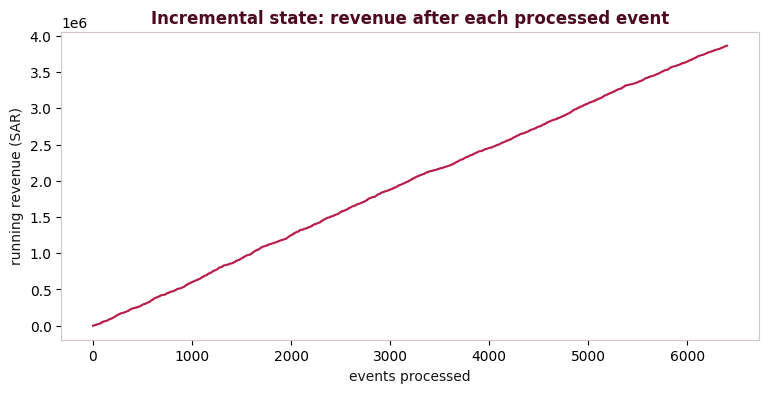

In [7]:
plt.plot(stream_history)
plt.title('Incremental state: revenue after each processed event')
plt.xlabel('events processed')
plt.ylabel('running revenue (SAR)')
plt.show()

## 3. Latency, throughput, and freshness are different

- **Latency:** time from event arrival to useful result.
- **Throughput:** events processed per unit time.
- **Freshness:** how far the available result lags behind the real world.

A system can have high throughput and still have poor latency if it buffers large batches.

In [8]:
architecture_scorecard = pd.DataFrame({
    'architecture':['batch','micro-batch','streaming'],
    'target_latency_seconds':[86400,300,2],
    'engineering_complexity_1to5':[1,3,5],
    'recovery_complexity_1to5':[1,3,5],
    'best_when':['deadline is periodic','minutes are acceptable','seconds change the decision']
})
architecture_scorecard

,architecture,target_latency_seconds,engineering_complexity_1to5,recovery_complexity_1to5,best_when
0,batch,86400,1,1,deadline is periodic
1,micro-batch,300,3,3,minutes are acceptable
2,streaming,2,5,5,seconds change the decision


## 4. Event time vs processing time

**Event time** describes when the event happened in the business world. **Processing time** describes when the compute engine handled it. Network delays, retries, mobile offline behavior, and upstream outages create out-of-order events.

In [9]:
sample = clean[['order_id','order_ts','event_value']].head(12).copy()
# Simulate variable network delay.
sample['arrival_ts'] = sample['order_ts'] + pd.to_timedelta(rng.integers(0, 180, len(sample)), unit='m')
sample['delay_min'] = (sample['arrival_ts'] - sample['order_ts']).dt.total_seconds()/60
sample.sort_values('arrival_ts')

,order_id,order_ts,event_value,arrival_ts,delay_min
0,105936,2026-01-01 00:03:00,49.29,2026-01-01 00:45:00,42.00
2,104193,2026-01-01 01:40:00,49.44,2026-01-01 02:00:00,20.00
1,105551,2026-01-01 01:24:00,284.07,2026-01-01 02:08:00,44.00
4,105731,2026-01-01 02:06:00,940.15,2026-01-01 02:20:00,14.00
3,105890,2026-01-01 01:56:00,28.41,2026-01-01 02:32:00,36.00
5,105234,2026-01-01 02:28:00,167.76,2026-01-01 03:02:00,34.00
6,104563,2026-01-01 03:07:00,469.55,2026-01-01 05:05:00,118.00
7,105829,2026-01-01 04:12:00,994.72,2026-01-01 06:17:00,125.00
8,101570,2026-01-01 04:43:00,"4,086.40",2026-01-01 06:39:00,116.00
11,100975,2026-01-01 05:49:00,"1,504.12",2026-01-01 06:47:00,58.00


## 5. Windowing: make infinite streams computable

Unbounded streams do not have a natural "final total." We usually scope aggregations to windows: **tumbling** (non-overlapping), **sliding** (overlapping), or **session** (activity separated by inactivity gaps).

In [10]:
windowed = clean.set_index('order_ts')
hourly = (windowed[windowed['status'].eq('completed')]
          .resample('6h')['event_value'].sum())
hourly.head(8)

order_ts
2026-01-01 00:00:00   4,225.85
2026-01-01 06:00:00   4,537.83
2026-01-01 12:00:00   3,806.53
2026-01-01 18:00:00   7,290.06
2026-01-02 00:00:00   1,313.73
2026-01-02 06:00:00   3,977.38
2026-01-02 12:00:00   6,061.90
2026-01-02 18:00:00   9,428.61
Freq: 6h, Name: event_value, dtype: float64

## 6. Stateful processing

State is information remembered across events: running totals, last-seen timestamps, open sessions, deduplication keys, model parameters, or partially built windows.

In [11]:
customer_state = defaultdict(lambda: {'orders':0, 'revenue':0.0})
for row in clean.head(2000).itertuples(index=False):
    if row.status == 'completed':
        s=customer_state[row.customer_id]
        s['orders'] += 1
        s['revenue'] += float(row.event_value)

pd.DataFrame.from_dict(customer_state, orient='index').sort_values('revenue', ascending=False).head()

,orders,revenue
229,9,"15,964.81"
5,11,"14,360.90"
165,9,"13,130.30"
226,8,"12,889.84"
95,9,"12,341.20"


## 7. Idempotency and duplicates

Retries are normal in distributed systems. An idempotent consumer can safely see the same event more than once without double-applying the business effect.

In [12]:
stream_with_retries = pd.concat([clean.head(1000), clean.head(30)], ignore_index=True)

seen=set(); total=0.0; duplicates=0
for row in stream_with_retries.itertuples(index=False):
    if row.order_id in seen:
        duplicates += 1
        continue
    seen.add(row.order_id)
    if row.status == 'completed':
        total += row.event_value

print('duplicates ignored:', duplicates)
print('deduplicated revenue:', round(total,2))

duplicates ignored: 30
deduplicated revenue: 600575.43


## 8. Partitions, ordering, and keys

Partitioning distributes work. Ordering is usually guaranteed only *within* a partition, not globally. Choose a key based on the state you need—for example, `customer_id` for per-customer fraud features.

In [13]:
partition_count=4
partition_demo=clean[['order_id','customer_id']].head(15).copy()
partition_demo['partition'] = partition_demo['customer_id'].map(lambda x: hash(int(x)) % partition_count)
partition_demo

,order_id,customer_id,partition
0,105936,52,0
1,105551,159,3
2,104193,129,1
3,105890,115,3
4,105731,92,0
5,105234,124,0
6,104563,209,1
7,105829,22,2
8,101570,291,3
9,105602,123,3


## 9. Backpressure and capacity

If producers generate events faster than consumers can sustainably process them, lag grows. Capacity planning needs peak arrival rate, service time, parallelism, state size, and acceptable recovery time—not just average load.

In [14]:
capacity = pd.DataFrame({
    'scenario':['normal','campaign peak','incident recovery'],
    'arrival_events_per_sec':[800,2400,1200],
    'consumer_capacity_per_sec':[1400,2800,2200]
})
capacity['headroom_per_sec']=capacity['consumer_capacity_per_sec']-capacity['arrival_events_per_sec']
capacity['stable']=capacity['headroom_per_sec']>0
capacity

,scenario,arrival_events_per_sec,consumer_capacity_per_sec,headroom_per_sec,stable
0,normal,800,1400,600,True
1,campaign peak,2400,2800,400,True
2,incident recovery,1200,2200,1000,True


## 10. Architecture selection framework

Ask in this order: **(1)** When does a decision lose value? **(2)** What is the tolerated data loss? **(3)** What ordering/state is required? **(4)** What is the peak rate? **(5)** What is the recovery objective? **(6)** Can the team operate the system 24/7?

In [15]:
def recommend_architecture(decision_deadline_seconds, needs_per_event_action=False):
    if needs_per_event_action or decision_deadline_seconds <= 10:
        return 'streaming'
    if decision_deadline_seconds <= 900:
        return 'micro-batch'
    return 'batch'

for sec in [2, 120, 3600, 86400]:
    print(sec, 'seconds ->', recommend_architecture(sec))

2 seconds -> streaming
120 seconds -> micro-batch
3600 seconds -> batch
86400 seconds -> batch


---
## References & further reading
- [Apache Kafka — Introduction to event streaming](https://kafka.apache.org/documentation/)
- [Apache Flink — stable documentation](https://nightlies.apache.org/flink/flink-docs-stable/)
- [Apache Flink — Timely Stream Processing](https://nightlies.apache.org/flink/flink-docs-stable/docs/concepts/time/)

<div class="dal-footer"><span><b>DAL | دال</b> · Build data fluency that survives production.</span><a href="https://daldata.ai">daldata.ai ↗</a></div>